# 03 · Urnas: extracciones con y sin reemplazo

La urna es el modelo básico de muestreo: bolas de colores, extracciones al azar, y la pregunta de qué colores salen. Este cuaderno compara las cuatro formas de extraer (con o sin orden, con o sin reemplazo), deduce las leyes binomial e hipergeométrica, y termina con la urna de Bayes y la urna de Pólya.

**Contenido**

1. Dibujar una urna
2. Las cuatro formas de extraer
3. Sin reemplazo: la ley hipergeométrica
4. Con reemplazo: la ley binomial
5. Hipergeométrica contra binomial (gráfica interactiva)
6. Varios colores: hipergeométrica multivariada y multinomial
7. Extracciones sucesivas e intercambiabilidad
8. Dos urnas y la fórmula de Bayes
9. La urna de Pólya
10. Un laboratorio de urnas con widgets

## 1. Dibujar una urna

Una urna con $5$ bolas rojas, $3$ azules y $2$ blancas:

> 🔴 🔴 🔴 🔴 🔴 🔵 🔵 🔵 ⚪ ⚪

Se extraen $3$ bolas. Dos resultados posibles:

| extracción | resultado | rojas | azules | blancas |
|---|---|:-:|:-:|:-:|
| sin reemplazo | 🔴 🔵 🔴 | 2 | 1 | 0 |
| con reemplazo | ⚪ ⚪ ⚪ | 0 | 0 | 3 |

El segundo resultado solo es posible **con reemplazo**: la urna tiene dos bolas blancas, y sin reemplazo no pueden salir tres.

Para dibujar urnas desde el código usamos los mismos símbolos.

In [1]:
from collections import Counter
from fractions import Fraction
from itertools import combinations, combinations_with_replacement, permutations, product
from math import comb, factorial, perm

import altair as alt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

rng = np.random.default_rng(2026)

BOLA = {"R": "🔴", "B": "🔵", "W": "⚪", "V": "🟢", "N": "⚫", "A": "🟡"}


def dibuja(bolas):
    """Cadena con un símbolo por bola; bolas es una sucesión de letras R, B, W, V, N, A."""
    return " ".join(BOLA[b] for b in bolas)


def urna(**colores):
    """urna(R=5, B=3) -> ['R','R','R','R','R','B','B','B']"""
    return [c for c, n in colores.items() for _ in range(n)]


U = urna(R=5, B=3, W=2)
display(Markdown(f"**Urna:** {dibuja(U)}"))
display(Markdown(f"**Una extracción de 3 sin reemplazo:** {dibuja(rng.choice(U, 3, replace=False))}"))
display(Markdown(f"**Una extracción de 3 con reemplazo:** {dibuja(rng.choice(U, 3, replace=True))}"))

**Urna:** 🔴 🔴 🔴 🔴 🔴 🔵 🔵 🔵 ⚪ ⚪

**Una extracción de 3 sin reemplazo:** 🔴 🔵 🔴

**Una extracción de 3 con reemplazo:** 🔴 🔴 🔴

## 2. Las cuatro formas de extraer

Se extraen $k$ bolas de una urna con $n$ bolas **distinguibles** (numeradas). Según importe el orden y se devuelva o no la bola, el número de resultados es:

| | ordenado | no ordenado |
|---|---|---|
| **sin reemplazo** | $n(n-1)\cdots(n-k+1)=\dfrac{n!}{(n-k)!}$ | $\dbinom nk$ |
| **con reemplazo** | $n^k$ | $\dbinom{n+k-1}{k}$ |

Las cuatro cuentas corresponden a `permutations`, `combinations`, `product` y `combinations_with_replacement` de `itertools`. Las verificamos con la urna 🔴 🔵 ⚪ 🟢 ($n=4$) y $k=2$.

In [2]:
bolas = ["R", "B", "W", "V"]
n, k = len(bolas), 2

esquemas = {
    "ordenado, sin reemplazo": (list(permutations(bolas, k)), perm(n, k)),
    "no ordenado, sin reemplazo": (list(combinations(bolas, k)), comb(n, k)),
    "ordenado, con reemplazo": (list(product(bolas, repeat=k)), n**k),
    "no ordenado, con reemplazo": (list(combinations_with_replacement(bolas, k)), comb(n + k - 1, k)),
}
for nombre, (resultados, formula) in esquemas.items():
    display(Markdown(f"**{nombre}** — {len(resultados)} resultados (fórmula: {formula})  \n"
                     + " · ".join(dibuja(r) for r in resultados)))

**ordenado, sin reemplazo** — 12 resultados (fórmula: 12)  
🔴 🔵 · 🔴 ⚪ · 🔴 🟢 · 🔵 🔴 · 🔵 ⚪ · 🔵 🟢 · ⚪ 🔴 · ⚪ 🔵 · ⚪ 🟢 · 🟢 🔴 · 🟢 🔵 · 🟢 ⚪

**no ordenado, sin reemplazo** — 6 resultados (fórmula: 6)  
🔴 🔵 · 🔴 ⚪ · 🔴 🟢 · 🔵 ⚪ · 🔵 🟢 · ⚪ 🟢

**ordenado, con reemplazo** — 16 resultados (fórmula: 16)  
🔴 🔴 · 🔴 🔵 · 🔴 ⚪ · 🔴 🟢 · 🔵 🔴 · 🔵 🔵 · 🔵 ⚪ · 🔵 🟢 · ⚪ 🔴 · ⚪ 🔵 · ⚪ ⚪ · ⚪ 🟢 · 🟢 🔴 · 🟢 🔵 · 🟢 ⚪ · 🟢 🟢

**no ordenado, con reemplazo** — 10 resultados (fórmula: 10)  
🔴 🔴 · 🔴 🔵 · 🔴 ⚪ · 🔴 🟢 · 🔵 🔵 · 🔵 ⚪ · 🔵 🟢 · ⚪ ⚪ · ⚪ 🟢 · 🟢 🟢

**Advertencia.** En los tres primeros esquemas los resultados son equiprobables. En el cuarto **no**: al extraer dos veces con reemplazo, la pareja no ordenada {🔴, 🔵} ocurre de dos maneras (🔴🔵 o 🔵🔴), mientras que {🔴, 🔴} solo de una. Contar multiconjuntos como si fueran equiprobables es un error clásico (el «error de D'Alembert»).

In [3]:
ordenados = list(product(bolas, repeat=2))
ley_no_ordenada = Counter(tuple(sorted(r)) for r in ordenados)
pd.DataFrame(
    {"resultado": [dibuja(r) for r in ley_no_ordenada],
     "probabilidad real": [Fraction(c, len(ordenados)) for c in ley_no_ordenada.values()],
     "si fueran equiprobables": Fraction(1, comb(n + 1, 2))}
)

,resultado,probabilidad real,si fueran equiprobables
0,🔴 🔴,1/16,1/10
1,🔵 🔴,1/8,1/10
2,🔴 ⚪,1/8,1/10
3,🔴 🟢,1/8,1/10
4,🔵 🔵,1/16,1/10
5,🔵 ⚪,1/8,1/10
6,🔵 🟢,1/8,1/10
7,⚪ ⚪,1/16,1/10
8,🟢 ⚪,1/8,1/10
9,🟢 🟢,1/16,1/10


## 3. Sin reemplazo: la ley hipergeométrica

Una urna tiene $N$ bolas: $K$ rojas y $N-K$ azules. Se extraen $k$ bolas **sin reemplazo**. Sea $X$ el número de rojas. Como los $\binom Nk$ subconjuntos son equiprobables,

$$\mathbb P(X=j)=\frac{\binom Kj\binom{N-K}{k-j}}{\binom Nk},\qquad \max(0,k-N+K)\le j\le\min(k,K).$$

Es la **ley hipergeométrica** $\mathrm{Hip}(N,K,k)$, con

$$\mathbb E[X]=k\frac KN,\qquad \operatorname{Var}(X)=k\frac KN\Big(1-\frac KN\Big)\frac{N-k}{N-1}.$$

**Ejemplo.** Urna con $N=10$ bolas, $K=4$ rojas: 🔴🔴🔴🔴🔵🔵🔵🔵🔵🔵. Se extraen $k=3$.

In [4]:
def hipergeometrica(j, N, K, k):
    return Fraction(comb(K, j) * comb(N - K, k - j), comb(N, k))

N, K, k = 10, 4, 3
U = urna(R=K, B=N - K)

# verificación por enumeración: las bolas se numeran para que sean distinguibles
subconjuntos = list(combinations(range(N), k))
conteo = Counter(sum(U[i] == "R" for i in s) for s in subconjuntos)

tabla = pd.DataFrame({
    "j rojas": range(k + 1),
    "ejemplo": [dibuja("R" * j + "B" * (k - j)) for j in range(k + 1)],
    "fórmula": [hipergeometrica(j, N, K, k) for j in range(k + 1)],
    "enumeración": [Fraction(conteo[j], len(subconjuntos)) for j in range(k + 1)],
})
tabla

,j rojas,ejemplo,fórmula,enumeración
0,0,🔵 🔵 🔵,1/6,1/6
1,1,🔴 🔵 🔵,1/2,1/2
2,2,🔴 🔴 🔵,3/10,3/10
3,3,🔴 🔴 🔴,1/30,1/30


In [5]:
X = stats.hypergeom(M=N, n=K, N=k)    # scipy: M = total, n = rojas, N = extraídas
print("scipy:", [round(X.pmf(j), 6) for j in range(k + 1)])
print(f"E[X] = {X.mean():.4f} = k K/N = {k * K / N}")
print(f"Var(X) = {X.var():.4f} = {k * K / N * (1 - K / N) * (N - k) / (N - 1):.4f}")

scipy: [np.float64(0.166667), np.float64(0.5), np.float64(0.3), np.float64(0.033333)]
E[X] = 1.2000 = k K/N = 1.2
Var(X) = 0.5600 = 0.5600


## 4. Con reemplazo: la ley binomial

Si cada bola se devuelve antes de la siguiente extracción, las extracciones son independientes y cada una es roja con probabilidad $p=K/N$. El número de rojas es **binomial**:

$$\mathbb P(X=j)=\binom kj p^j(1-p)^{k-j},\qquad \mathbb E[X]=kp,\qquad \operatorname{Var}(X)=kp(1-p).$$

Las medias coinciden; la varianza sin reemplazo es menor por el **factor de corrección por población finita** $\frac{N-k}{N-1}<1$: al no devolver bolas, la composición de la urna «se corrige» hacia la proporción original.

In [6]:
p = K / N
conteo_con = Counter(sum(U[i] == "R" for i in s) for s in product(range(N), repeat=k))
pd.DataFrame({
    "j rojas": range(k + 1),
    "sin reemplazo": [float(hipergeometrica(j, N, K, k)) for j in range(k + 1)],
    "con reemplazo (fórmula)": [stats.binom.pmf(j, k, p) for j in range(k + 1)],
    "con reemplazo (enumeración)": [conteo_con[j] / N**k for j in range(k + 1)],
}).round(4)

,j rojas,sin reemplazo,con reemplazo (fórmula),con reemplazo (enumeración)
0,0,0.1667,0.216,0.216
1,1,0.5000,0.432,0.432
2,2,0.3000,0.288,0.288
3,3,0.0333,0.064,0.064


Simulación de las dos formas de extraer, $20\,000$ veces cada una:

In [7]:
def simula(U, k, reemplazo, veces):
    U = np.array(U)
    if reemplazo:
        idx = rng.integers(0, len(U), size=(veces, k))
    else:
        idx = np.argsort(rng.random((veces, len(U))), axis=1)[:, :k]   # k índices distintos
    return (U[idx] == "R").sum(axis=1)

sin = simula(U, k, False, 20_000)
con = simula(U, k, True, 20_000)
print(f"sin reemplazo: media {sin.mean():.3f}, varianza {sin.var():.3f}")
print(f"con reemplazo: media {con.mean():.3f}, varianza {con.var():.3f}  (kp(1-p) = {k * p * (1 - p):.3f})")

sin reemplazo: media 1.199, varianza 0.561
con reemplazo: media 1.214, varianza 0.732  (kp(1-p) = 0.720)


## 5. Hipergeométrica contra binomial

Si la urna es muy grande comparada con la muestra, devolver o no la bola casi no importa: cuando $N\to\infty$ con $K/N\to p$ fijo,

$$\frac{\binom Kj\binom{N-K}{k-j}}{\binom Nk}\longrightarrow\binom kj p^j(1-p)^{k-j}.$$

La gráfica es **interactiva** (Altair): mueve el deslizador para cambiar el tamaño $N$ de la urna, con $k=10$ extracciones y proporción de rojas $p=0.3$. Las barras son la hipergeométrica y los puntos la binomial.

In [8]:
k, p = 10, 0.3
filas = []
for N in [10, 20, 30, 50, 100, 200, 500, 1000]:
    K = round(p * N)
    for j in range(k + 1):
        filas.append({"N": N, "j": j, "ley": "sin reemplazo (hipergeométrica)", "probabilidad": stats.hypergeom.pmf(j, N, K, k)})
        filas.append({"N": N, "j": j, "ley": "con reemplazo (binomial)", "probabilidad": stats.binom.pmf(j, k, K / N)})
datos = pd.DataFrame(filas)

N_sel = alt.param(name="N", value=10,
                  bind=alt.binding_select(options=sorted(datos.N.unique().tolist()), name="Tamaño de la urna N: "))
base = alt.Chart(datos).transform_filter(alt.datum.N == N_sel).encode(
    x=alt.X("j:O", title="número de rojas j"),
    y=alt.Y("probabilidad:Q", scale=alt.Scale(domain=[0, 0.45])),
    tooltip=["ley", "j", alt.Tooltip("probabilidad:Q", format=".4f")],
)
barras = base.transform_filter(alt.datum.ley == "sin reemplazo (hipergeométrica)").mark_bar(opacity=0.6, color="#d62728")
puntos = base.transform_filter(alt.datum.ley == "con reemplazo (binomial)").mark_point(filled=True, size=80, color="#1f77b4")
(barras + puntos).add_params(N_sel).properties(width=480, height=260, title="Hipergeométrica (barras) y binomial (puntos), k = 10, p = 0.3")

alt.LayerChart(...)

La distancia en variación total entre ambas leyes decrece como $k/N$:

In [9]:
for N in [20, 100, 1000, 10_000]:
    K = round(p * N)
    j = np.arange(k + 1)
    dtv = 0.5 * np.abs(stats.hypergeom.pmf(j, N, K, k) - stats.binom.pmf(j, k, K / N)).sum()
    print(f"N = {N:>6}:  d_TV = {dtv:.5f}")

N =     20:  d_TV = 0.15871
N =    100:  d_TV = 0.02555
N =   1000:  d_TV = 0.00245
N =  10000:  d_TV = 0.00024


## 6. Varios colores

Con $N=23$ bolas, $8$ blancas, $6$ azules y $9$ rojas:

> ⚪⚪⚪⚪⚪⚪⚪⚪ 🔵🔵🔵🔵🔵🔵 🔴🔴🔴🔴🔴🔴🔴🔴🔴

se extraen $6$. **Sin reemplazo**, el vector de colores $(W,B,R)$ tiene ley **hipergeométrica multivariada**:

$$\mathbb P(W=a,B=b,R=c)=\frac{\binom8a\binom6b\binom9c}{\binom{23}6},\qquad a+b+c=6.$$

**Con reemplazo**, tiene ley **multinomial**:

$$\mathbb P(W=a,B=b,R=c)=\frac{6!}{a!\,b!\,c!}\Big(\frac8{23}\Big)^a\Big(\frac6{23}\Big)^b\Big(\frac9{23}\Big)^c.$$

Comparamos algunos eventos (los del cuaderno 02 son las tres primeras filas).

In [10]:
colores = {"W": 8, "B": 6, "R": 9}
total, m = sum(colores.values()), 6
probs = np.array(list(colores.values())) / total

def sin_reemplazo(a, b, c):
    return comb(8, a) * comb(6, b) * comb(9, c) / comb(total, m)

def con_reemplazo(a, b, c):
    return stats.multinomial.pmf([a, b, c], m, probs)

eventos = {"6 rojas": [(0, 0, 6)],
           "3 azules, 2 blancas, 1 roja": [(2, 3, 1)],
           "exactamente 4 blancas": [(4, b, 2 - b) for b in range(3)],
           "un solo color": [(6, 0, 0), (0, 6, 0), (0, 0, 6)],
           "los tres colores": [(a, b, m - a - b) for a in range(1, 5) for b in range(1, 6 - a)]}
pd.DataFrame({
    "evento": list(eventos),
    "sin reemplazo": [sum(sin_reemplazo(*t) for t in ts) for ts in eventos.values()],
    "con reemplazo": [sum(con_reemplazo(*t) for t in ts) for ts in eventos.values()],
}).round(5)

,evento,sin reemplazo,con reemplazo
0,6 rojas,0.00083,0.00359
1,"3 azules, 2 blancas, 1 roja",0.04993,0.05043
2,exactamente 4 blancas,0.07281,0.09338
3,un solo color,0.00112,0.00568
4,los tres colores,0.79919,0.71482


«Seis bolas del mismo color» es mucho más probable con reemplazo: cada extracción vuelve a encontrar la urna completa, mientras que sin reemplazo cada bola extraída agota su color. Por la razón inversa, «los tres colores» es más probable sin reemplazo.

## 7. Extracciones sucesivas e intercambiabilidad

Se extraen bolas una por una, **sin reemplazo**, de 🔴🔴🔴🔵🔵 ($3$ rojas, $2$ azules). ¿Cuál es la probabilidad de que la **segunda** sea roja?

Por probabilidad total,

$$\mathbb P(R_2)=\mathbb P(R_2\mid R_1)\mathbb P(R_1)+\mathbb P(R_2\mid B_1)\mathbb P(B_1)=\frac24\cdot\frac35+\frac34\cdot\frac25=\frac35.$$

Igual que la primera. No es casualidad: los $5!$ órdenes son equiprobables, de modo que la sucesión de colores es **intercambiable** y cada posición tiene la misma ley marginal.

In [11]:
U5 = urna(R=3, B=2)
ordenes = list(permutations(range(5)))
for posicion in range(5):
    prob = Fraction(sum(U5[o[posicion]] == "R" for o in ordenes), len(ordenes))
    print(f"P(la bola {posicion + 1} es {BOLA['R']}) = {prob}")

P(la bola 1 es 🔴) = 3/5
P(la bola 2 es 🔴) = 3/5
P(la bola 3 es 🔴) = 3/5
P(la bola 4 es 🔴) = 3/5
P(la bola 5 es 🔴) = 3/5


## 8. Dos urnas y la fórmula de Bayes

| urna I | urna II |
|:-:|:-:|
| 🔴🔴🔴🔵 | 🔴🔵🔵🔵🔵🔵 |

Se elige una urna lanzando una moneda y se extrae una bola: sale 🔴. ¿Cuál es la probabilidad de que venga de la urna I?

$$\mathbb P(I\mid R)=\frac{\mathbb P(R\mid I)\,\mathbb P(I)}{\mathbb P(R\mid I)\mathbb P(I)+\mathbb P(R\mid II)\mathbb P(II)}=\frac{\frac34\cdot\frac12}{\frac34\cdot\frac12+\frac16\cdot\frac12}=\frac{9}{11}.$$

In [12]:
urnas = {"I": urna(R=3, B=1), "II": urna(R=1, B=5)}
eleccion = rng.choice(["I", "II"], size=100_000)
bola = np.array([rng.choice(urnas[u]) for u in eleccion])
print("P(I | 🔴) por simulación:", np.mean(eleccion[bola == "R"] == "I").round(4), "  exacta: 9/11 =", round(9 / 11, 4))

P(I | 🔴) por simulación: 0.8187   exacta: 9/11 = 0.8182


## 9. La urna de Pólya

En la urna de **Pólya** cada bola extraída se devuelve **junto con otra del mismo color**: el éxito se refuerza. Si se empieza con 🔴🔵, tras $n$ extracciones el número de rojas añadidas es **uniforme** en $\{0,\dots,n\}$, y la proporción de rojas converge casi seguramente a una variable $\mathrm{Unif}(0,1)$. En general, empezando con $a$ rojas y $b$ azules, el límite tiene ley $\mathrm{Beta}(a,b)$.

Cada trayectoria se estabiliza, pero en un valor **aleatorio**: a diferencia de la urna con reemplazo, la proporción no olvida sus primeras extracciones.

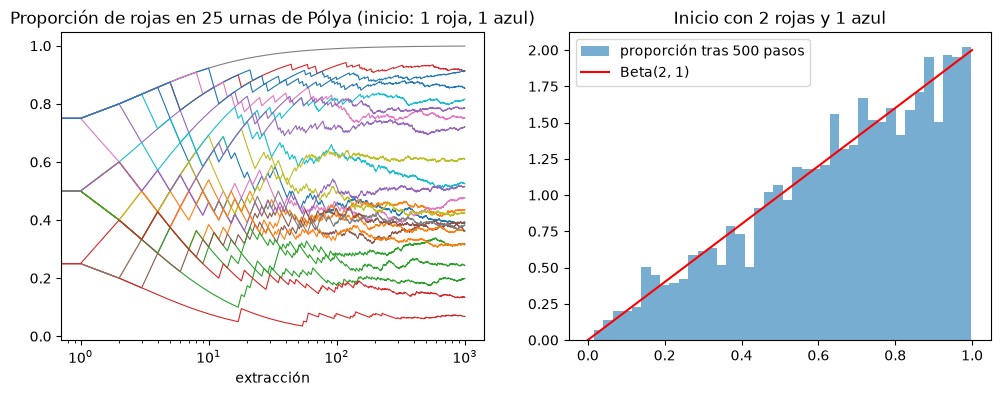

In [13]:
def polya(a, b, pasos):
    rojas, azules = a, b
    proporciones = []
    for _ in range(pasos):
        if rng.random() < rojas / (rojas + azules):
            rojas += 1
        else:
            azules += 1
        proporciones.append(rojas / (rojas + azules))
    return np.array(proporciones)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for _ in range(25):
    ax1.plot(polya(1, 1, 1000), lw=0.8)
ax1.set_xscale("log")
ax1.set_title("Proporción de rojas en 25 urnas de Pólya (inicio: 1 roja, 1 azul)")
ax1.set_xlabel("extracción")

finales = [polya(2, 1, 500)[-1] for _ in range(3000)]
ax2.hist(finales, bins=40, density=True, alpha=0.6, label="proporción tras 500 pasos")
x = np.linspace(0, 1, 200)
ax2.plot(x, stats.beta.pdf(x, 2, 1), "r", label="Beta(2, 1)")
ax2.set_title("Inicio con 2 rojas y 1 azul")
ax2.legend()
plt.show()

## 10. Un laboratorio de urnas con widgets

La celda siguiente crea controles (`ipywidgets`): número de bolas de cada color, número de extracciones y si hay reemplazo. Muestra una extracción dibujada con colores y la ley simulada del número de rojas junto a la exacta. Los widgets necesitan un kernel activo (Jupyter, VS Code o Colab); en la vista estática de GitHub solo se ve el resultado inicial.

In [14]:
import ipywidgets as widgets


def laboratorio(rojas=4, azules=6, blancas=0, extracciones=5, reemplazo=False, repeticiones=5000):
    U = urna(R=rojas, B=azules, W=blancas)
    N, K = len(U), rojas
    if not reemplazo and extracciones > N:
        display(Markdown("⚠️ Sin reemplazo no se pueden extraer más bolas de las que hay."))
        return
    display(Markdown(f"**Urna** ({N} bolas): {dibuja(U)}  \n"
                     f"**Una extracción:** {dibuja(rng.choice(U, extracciones, replace=reemplazo))}"))
    X = simula(U, extracciones, reemplazo, repeticiones)
    j = np.arange(extracciones + 1)
    exacta = stats.binom.pmf(j, extracciones, K / N) if reemplazo else stats.hypergeom.pmf(j, N, K, extracciones)
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.bar(j, np.bincount(X, minlength=extracciones + 1) / repeticiones, alpha=0.6, color="tab:red", label="simulación")
    ax.plot(j, exacta, "ko", label="binomial" if reemplazo else "hipergeométrica")
    ax.set_xlabel("número de rojas")
    ax.legend()
    plt.show()


widgets.interact(
    laboratorio,
    rojas=widgets.IntSlider(4, 0, 15, description="🔴 rojas"),
    azules=widgets.IntSlider(6, 0, 15, description="🔵 azules"),
    blancas=widgets.IntSlider(0, 0, 15, description="⚪ blancas"),
    extracciones=widgets.IntSlider(5, 1, 20, description="extracciones"),
    reemplazo=widgets.Checkbox(False, description="con reemplazo"),
    repeticiones=widgets.fixed(5000),
);

interactive(children=(IntSlider(value=4, description='🔴 rojas', max=15), IntSlider(value=6, description='🔵 azu…

## Ejercicios

1. Una urna tiene 🔴🔴🔴🔴🔴🔵🔵🔵. Se extraen $4$ bolas. Calcula la probabilidad de obtener exactamente $2$ rojas con y sin reemplazo, y explica cuál es mayor.
2. Demuestra la fórmula de la varianza hipergeométrica escribiendo $X=\sum_{i=1}^k\mathbf 1_{\{\text{la } i\text{-ésima bola es roja}\}}$ y usando la intercambiabilidad para calcular las covarianzas.
3. En la urna de Pólya con inicio 🔴🔵, demuestra por inducción que el número de rojas añadidas tras $n$ pasos es uniforme en $\{0,\dots,n\}$.
4. ¿Cuántas extracciones con reemplazo de 🔴🔵⚪🟢 se necesitan, en promedio, para ver los cuatro colores? (Problema del coleccionista: $4\,(1+\frac12+\frac13+\frac14)$.)